# Kerr AGP: saved jobs, local T1 compensation, and theory

Set the data directory, mu and independently measured M1 T1 below, then run
the cells in order. These are the complete disorder groups through JOB00324,
including W=0. W=160 is incomplete and is not included.

The existing classes load saved readout-corrected results and calculate AGP.
HDF5 files are read without IQ shots; this notebook does not save over them.
The plot reproduces the curve values, without uncertainty propagation/error bars.

In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from experiments.qsim.agp import CentralBosonAGPExperiment, CentralBosonAGPDisorderScan
from experiments.qsim.fock_population import FockPopulationExperiment
from fitting.qsim.agp import finite_time_agp
from fitting.qsim.mbr_hamiltonian import fixed_n_hamiltonian

In [26]:
import json
import h5py

def import_jobs_by_w(data_dir, first_job, last_job, *, ro_stor=0, photons=3):
    groups = {}
    for path in sorted(Path(data_dir).glob("JOB-*_FockPopulationExperiment.h5")):
        job_id = path.name.split("_", 1)[0]
        if not first_job <= job_id <= last_job:
            continue
        with h5py.File(path, "r") as handle:
            expt = json.loads(handle.attrs["config"])["expt"]
        if expt["ro_stor"] != ro_stor or sum(expt["occupations"]) != photons:
            continue
        w = round(1000 * np.sqrt(np.mean(np.square(expt["detunings"]))), 6)
        groups.setdefault(w, []).append(job_id)
    return dict(sorted(groups.items()))

In [33]:
# DATA_DIR = Path(r"C:\experiments\agp_k44_first_scan\data")
DATA_DIR = Path(r"C:\experiments\agp_k44_first_scan\data")

MU_KHZ = 10.0  # None uses the existing default g * L / D.
T1_M_US = 221.19395791954372  # JOB-20261019-00046_T1CavityExperiment, independent calibration.

# JOBS_BY_W = {
#     0: ["JOB-20261023-00515", "JOB-20261023-00516", "JOB-20261023-00518",
#         "JOB-20261023-00519", "JOB-20261023-00525"],
#     20: ["JOB-20261024-00002", "JOB-20261024-00003", "JOB-20261024-00009",
#          "JOB-20261024-00010", "JOB-20261024-00027"],
#     40: ["JOB-20261024-00028", "JOB-20261024-00033", "JOB-20261024-00034",
#          "JOB-20261024-00039", "JOB-20261024-00040"],
#     60: ["JOB-20261024-00063", "JOB-20261024-00064", "JOB-20261024-00071",
#          "JOB-20261024-00072", "JOB-20261024-00079"],
#     80: ["JOB-20261024-00080", "JOB-20261024-00086", "JOB-20261024-00087",
#          "JOB-20261024-00107", "JOB-20261024-00108"],
#     100: ["JOB-20261024-00161", "JOB-20261024-00162", "JOB-20261024-00176",
#           "JOB-20261024-00177", "JOB-20261024-00226"],
#     120: ["JOB-20261024-00227", "JOB-20261024-00244", "JOB-20261024-00245",
#           "JOB-20261024-00278", "JOB-20261024-00279"],
#     140: ["JOB-20261024-00313", "JOB-20261024-00314", "JOB-20261024-00320",
#           "JOB-20261024-00321", "JOB-20261024-00323"],
#     160: ["JOB-20261024-00324", "JOB-20261024-00326", "JOB-20261024-00327", "JOB-20261024-00333",
#           "JOB-20261024-00334"],
#     180: ["JOB-20261024-00340", "JOB-20261024-00341", "JOB-20261024-00347", "JOB-20261024-00348",
#           "JOB-20261024-00349"],
#     200: ["JOB-20261024-00350", "JOB-20261025-00001", "JOB-20261025-00002", "JOB-20261025-00003",
#           "JOB-20261025-00004"],
# }
# JOBS_BY_W = import_jobs_by_w(
#     r"C:\experiments\agp_k44_first_scan\data",
#     "JOB-20261023-00253",
#     "JOB-20261023-00294",
#     ro_stor=7,  
# )


JOBS_BY_W = {
    0: ['JOB-20261023-00253',
 'JOB-20261023-00255',
 'JOB-20261023-00257',
 'JOB-20261023-00258',
 'JOB-20261023-00259',
 'JOB-20261023-00260',
 'JOB-20261023-00261',
 'JOB-20261023-00262',
 'JOB-20261023-00263',
 'JOB-20261023-00264',
 'JOB-20261023-00266',
 'JOB-20261023-00268',
 'JOB-20261023-00270',
 'JOB-20261023-00272',
 'JOB-20261023-00274']
,
    20: ['JOB-20261023-00276',
 'JOB-20261023-00278',
 'JOB-20261023-00280',
 'JOB-20261023-00282',
 'JOB-20261023-00284',
 'JOB-20261023-00285',
 'JOB-20261023-00286',
 'JOB-20261023-00287',
 'JOB-20261023-00288',
 'JOB-20261023-00289',
 'JOB-20261023-00290',
 'JOB-20261023-00291',
 'JOB-20261023-00292',
 'JOB-20261023-00293',
 'JOB-20261023-00294']
,
}

## Assemble and analyze with the existing classes

Saved: C:\experiments\agp_k44_first_scan\assembled_data\261102_161533_CentralBosonAGPDisorderScan.yaml


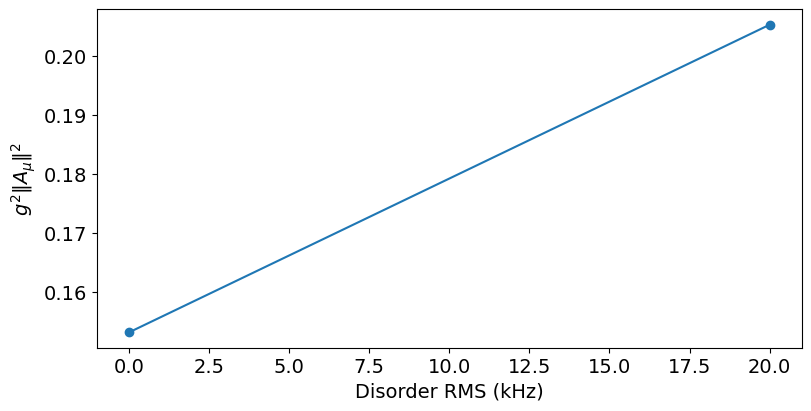

In [34]:
from pathlib import Path

from experiments.qsim.agp import (
    CentralBosonAGPExperiment,
    CentralBosonAGPDisorderScan,
    direction_sector,
)
from experiments.qsim.fock_population import FockPopulationExperiment


parts, scan = [], None

for w, job_ids in JOBS_BY_W.items():
    paths = [
        DATA_DIR / f"{job_id}_FockPopulationExperiment.h5"
        for job_id in job_ids
    ]

    if not paths or not all(path.is_file() for path in paths):
        print(f"W={w:g}: missing HDF5; skipped")
        continue

    jobs = [
        FockPopulationExperiment.from_h5file(path, load_shots=False)
        for path in paths
    ]

    expt = jobs[0].cfg.expt
    direction = int(expt.ro_stor)

    expected = sorted(
        (tuple(state), direction)
        for state in direction_sector(
            sum(expt.occupations), expt.swap_stors, direction
        )
    )
    actual = sorted(
        (tuple(job.cfg.expt.occupations), int(job.cfg.expt.ro_stor))
        for job in jobs
    )

    if actual != expected:
        print(f"W={w:g}: incomplete ({len(actual)}/{len(expected)}); skipped")
        continue

    parts.append(
        CentralBosonAGPExperiment.from_children(
            jobs,
            job_ids=job_ids,
            direction=direction,
            disorder_khz=w,
        )
    )

if parts:
    scan = CentralBosonAGPDisorderScan.from_children(parts)
    scan.analyze(mu=MU_KHZ)
    manifest_path = scan.save()
    print(f"Saved: {manifest_path}")
    scan.display()
else:
    print("No complete W groups; nothing saved.")

In [35]:
parts = []
for disorder_khz, job_ids in JOBS_BY_W.items():
    jobs = [FockPopulationExperiment.from_h5file(
        DATA_DIR / f"{job_id}_FockPopulationExperiment.h5", load_shots=False)
        for job_id in job_ids]
    parts.append(CentralBosonAGPExperiment.from_children(
        jobs, job_ids=job_ids, direction=7, disorder_khz=disorder_khz))

scan = CentralBosonAGPDisorderScan.from_children(parts)
scan.analyze(mu=MU_KHZ)

# The recorded g and Kerr are shared by this fixed-Hamiltonian disorder scan.
first = scan.children[0]
job = first.children[0]
storage_indices = np.asarray(first.swap_stors) - 1
couplings_MHz = np.asarray(job.recorded_derived_params()["couplings_MHz"])[storage_indices]
g_MHz = float(np.mean(np.abs(couplings_MHz)))
kerr_MHz = float(job.cfg.device.manipulate.kerr[0])

## Local T1 approximation, applied to each Kerr trace

Multiply every measured P(t) row by exp(2t/T1_M), then form the correlation
and use the existing kernel integral. This cancels the explicit local loss
term, but is not an exact inverse of the coupled dynamics. No T2 correction
or theory-based adjustment enters the experimental curves.

In [36]:
scan.data["agp_t1_list"] = []
for part in scan.children:
    data = part.data
    times = data["time_us"]
    initial = data["occupations"][:, 0].astype(float)
    initial = initial * (initial - 1) / 2
    population = (data["n2_mean_corrected"] - data["n_mean_corrected"]) / 2
    population_t1 = population * np.exp(2 * times / T1_M_US)
    data["C1_t1"] = (initial / data["sector_dimension"]) @ population_t1

    result = finite_time_agp(times, data["C1_t1"], data["agp_mu"] / 1000)
    data["agp_t1"] = float(result["values"] * (2 * np.pi * g_MHz)**2)
    scan.data["agp_t1_list"].append(data["agp_t1"])

## Independent full-AGP reference

Reuse the existing fixed-N Hamiltonian and its eigenvectors. The spectral sum
uses cyclic MHz consistently, so no extra 2pi appears in this expression.
This static-Hamiltonian reference is plotted only; it does not correct data.

In [37]:
scan.data["agp_theory_list"] = []
for part in scan.children:
    model = fixed_n_hamiltonian(
        part.photon_sector_number, len(part.swap_stors) + 1,
        part.detunings, couplings_MHz, kerr_MHz)
    hub_number = np.asarray(model.fock_basis)[:, 0]
    probe = hub_number * (hub_number - 1) / 2
    matrix_elements = model.states.conj().T @ (probe[:, None] * model.states)
    gaps_MHz = model.energies_MHz[:, None] - model.energies_MHz[None, :]
    mu_MHz = part.data["agp_mu"] / 1000
    value = g_MHz**2 / len(probe) * np.sum(
        np.abs(matrix_elements)**2 * gaps_MHz**2 / (gaps_MHz**2 + mu_MHz**2)**2)
    scan.data["agp_theory_list"].append(float(value))

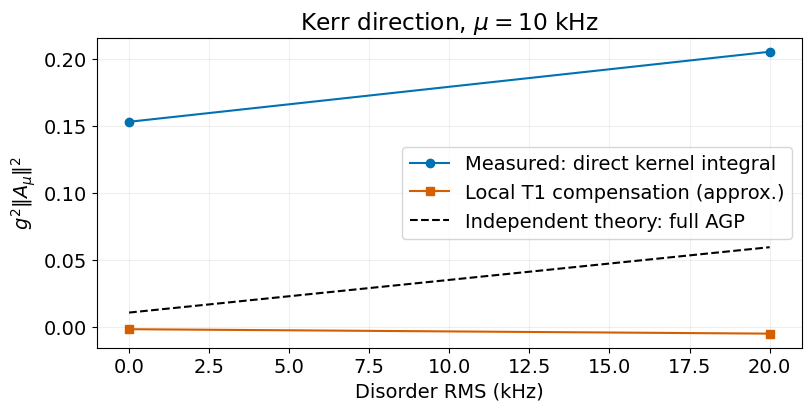

In [38]:
fig, ax = scan.display()
ax.lines[0].set(color="#0072B2", label="Measured: direct kernel integral")
ax.plot(scan.data["disorder_khz"], scan.data["agp_t1_list"], "s-",
        color="#D55E00", label="Local T1 compensation (approx.)")
ax.plot(scan.data["disorder_khz"], scan.data["agp_theory_list"], "k--",
        label="Independent theory: full AGP")
ax.set_title(rf"Kerr direction, $\mu={scan.data['agp_mu_list'][0]:g}$ kHz")
ax.grid(alpha=0.2)
ax.legend()
plt.show()